# Clustering

## 1. Introdução

### **Grupo G15 – Teammates**
- **Nuno Miguel Rodrigues da Silva (a25417)**  
- **Hugo Francisco Pereira Azevedo (a25431)**  
- **Tiago André Alves Castro (a25434)**  
- **Gonçalo Edi Pinto Homem de Figueiredo (a26747)**  
- **João Miguel Santos Silva Campos Cunha (a23519)**  

Este notebook corresponde ao **Notebook 2 – Clustering** do Projeto 02 da unidade curricular de **Inteligência Artificial**.

O objetivo deste trabalho é aplicar métodos de **aprendizagem não supervisionada**, em particular o algoritmo **K-Means**, para identificar grupos de jogadores com características semelhantes no dataset FIFA.

Mais concretamente, este notebook inclui:
- Definição do **objetivo de negócio** associado ao clustering;  
- Descrição do **dataset** utilizado;  
- **Preparação** e seleção dos dados relevantes para clustering;  
- Aplicação e **otimização** do algoritmo K-Means;  
- Análise das **características de cada cluster**, incluindo atributos numéricos e o atributo categórico **positions**;  
- **Conclusão** com análise dos resultados e lições aprendidas.


## 2. Dataset

### 2.1 Fonte do Dataset
O dataset utilizado neste projeto é proveniente do Kaggle:

- **FIFA Players Ratings Dataset**  
- URL: https://www.kaggle.com/datasets/rishidamarla/fifa-players-ratings  

Para este notebook é utilizada a versão **fifa_cleaned.csv**, previamente tratada no Notebook 1.

---

### 2.2 Metadados do Dataset
Serão analisados:
- Número de jogadores (linhas);  
- Número de atributos (colunas);  
- Tipos de dados;  
- Primeiras linhas do dataset.


In [5]:
import pandas as pd
import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

pd.set_option('display.max_rows', 100)
pd.set_option('display.max_columns', None)

df = pd.read_csv('fifa_cleaned.csv')
df

,id,name,full_name,birth_date,age,height_cm,weight_kgs,positions,nationality,overall_rating,potential,value_euro,wage_euro,preferred_foot,international_reputation(1-5),weak_foot(1-5),skill_moves(1-5),work_rate,body_type,release_clause_euro,club_team,club_rating,club_position,club_jersey_number,club_join_date,contract_end_year,national_team,national_rating,national_team_position,national_jersey_number,crossing,finishing,heading_accuracy,short_passing,volleys,dribbling,curve,freekick_accuracy,long_passing,ball_control,acceleration,sprint_speed,agility,reactions,balance,shot_power,jumping,stamina,strength,long_shots,aggression,interceptions,positioning,vision,penalties,composure,marking,standing_tackle,sliding_tackle,GK_diving,GK_handling,GK_kicking,GK_positioning,GK_reflexes,tags,traits,LS,ST,RS,LW,LF,CF,RF,RW,LAM,CAM,RAM,LM,LCM,CM,RCM,RM,LWB,LDM,CDM,RDM,RWB,LB,LCB,CB,RCB,RB
0,158023,L. Messi,Lionel Andrés Messi Cuccittini,1987-06-24,31,170.18,72.1,"CF,RW,ST",Argentina,94,94,110500000.0,565000.0,Left,5,4,4,Medium/ Low,Messi,226500000.0,FC Barcelona,86.0,RW,10.0,2004-07-01,2021,Argentina,82.0,RF,10.0,86,95,70,92,86,97,93,94,89,96,91,86,93,95,95,85,68,72,66,94,48,22,94,94,75,96,33,28,26,6,11,15,14,8,"#Dribbler,#Distance Shooter,#Crosser,#FK Speci...","Finesse Shot,Long Shot Taker (CPU AI Only),Spe...",89+2,89+2,89+2,93+2,93+2,93+2,93+2,93+2,93+2,93+2,93+2,91+2,85+2,85+2,85+2,91+2,64+2,61+2,61+2,61+2,64+2,59+2,48+2,48+2,48+2,59+2
1,190460,C. Eriksen,Christian Dannemann Eriksen,1992-02-14,27,154.94,76.2,"CAM,RM,CM",Denmark,88,89,69500000.0,205000.0,Right,3,5,4,High/ Medium,Lean,133800000.0,Tottenham Hotspur,83.0,LCM,23.0,2013-08-30,2020,Denmark,78.0,CAM,10.0,88,81,52,91,80,84,86,87,89,91,76,73,80,88,81,84,50,92,58,89,46,56,84,91,67,88,59,57,22,9,14,7,7,6,"#Playmaker ,#Crosser,#FK Specialist,#Complete...","Flair,Long Shot Taker (CPU AI Only),Playmaker ...",79+3,79+3,79+3,85+3,84+3,84+3,84+3,85+3,86+3,86+3,86+3,86+3,85+3,85+3,85+3,86+3,71+3,71+3,71+3,71+3,71+3,66+3,57+3,57+3,57+3,66+3
2,195864,P. Pogba,Paul Pogba,1993-03-15,25,190.50,83.9,"CM,CAM",France,88,91,73000000.0,255000.0,Right,4,4,5,High/ Medium,Normal,144200000.0,Manchester United,82.0,LCM,6.0,2016-08-09,2021,France,84.0,RDM,6.0,80,75,75,86,85,87,85,82,90,90,71,79,76,82,66,90,83,88,87,82,78,64,82,88,82,87,63,67,67,5,6,2,4,3,"#Dribbler,#Playmaker ,#Strength,#Complete Mid...","Flair,Long Passer (CPU AI Only),Long Shot Take...",81+3,81+3,81+3,82+3,83+3,83+3,83+3,82+3,84+3,84+3,84+3,83+3,84+3,84+3,84+3,83+3,76+3,77+3,77+3,77+3,76+3,74+3,72+3,72+3,72+3,74+3
3,198219,L. Insigne,Lorenzo Insigne,1991-06-04,27,162.56,59.0,"LW,ST",Italy,88,88,62000000.0,165000.0,Right,3,4,4,High/ Medium,Normal,105400000.0,Napoli,82.0,LS,24.0,2010-07-01,2022,Italy,83.0,LW,10.0,86,77,56,85,74,90,87,77,78,93,94,86,94,83,93,75,53,75,44,84,34,26,83,87,61,83,51,24,22,8,4,14,9,10,"#Speedster,#Dribbler,#Crosser,#Acrobat","Finesse Shot,Long Shot Taker (CPU AI Only),Spe...",78+3,78+3,78+3,86+3,85+3,85+3,85+3,86+3,86+3,86+3,86+3,86+3,78+3,78+3,78+3,86+3,63+3,58+3,58+3,58+3,63+3,58+3,44+3,44+3,44+3,58+3
4,201024,K. Koulibaly,Kalidou Koulibaly,1991-06-20,27,187.96,88.9,CB,Senegal,88,91,60000000.0,135000.0,Right,3,3,2,High/ High,Normal,106500000.0,Napoli,82.0,LCB,26.0,2014-07-01,2021,NaN,NaN,NaN,NaN,30,22,83,68,14,69,28,28,60,63,70,75,50,82,40,55,81,75,94,15,87,88,24,49,33,80,91,88,87,7,11,7,13,5,"#Tackling ,#Tactician ,#Strength,#Complete Def...",Power Header,53+3,53+3,53+3,53+3,54+3,54+3,54+3,53+3,55+3,55+3,55+3,57+3,61+3,61+3,61+3,57+3,73+3,77+3,77+3,77+3,73+3,76+3,85+3,85+3,85+3,76+3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17949,204322,R. McKenzie,Rory McKenzie,1993-10-07,25,175.26,74.

### 2.3 Análise Exploratória dos Dados (EDA)

Nesta secção são apresentados:
- Número de linhas e colunas do dataset;  
- Estatísticas descritivas dos atributos numéricos;  
- Valores em falta por coluna.


In [6]:
print('Número de linhas:', df.shape[0])
print('Número de colunas:', df.shape[1])

df.describe()

Número de linhas: 17954
Número de colunas: 92


,id,age,height_cm,weight_kgs,overall_rating,potential,value_euro,wage_euro,international_reputation(1-5),weak_foot(1-5),skill_moves(1-5),release_clause_euro,club_rating,club_jersey_number,national_rating,national_jersey_number,crossing,finishing,heading_accuracy,short_passing,volleys,dribbling,curve,freekick_accuracy,long_passing,ball_control,acceleration,sprint_speed,agility,reactions,balance,shot_power,jumping,stamina,strength,long_shots,aggression,interceptions,positioning,vision,penalties,composure,marking,standing_tackle,sliding_tackle,GK_diving,GK_handling,GK_kicking,GK_positioning,GK_reflexes
count,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,1.769900e+04,17708.000000,17954.000000,17954.000000,17954.000000,1.611700e+04,17940.000000,17940.000000,857.000000,857.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000
mean,215411.087780,25.565445,174.946921,75.301047,66.240169,71.430935,2.479280e+06,9902.134628,1.111674,2.945695,2.361034,4.622522e+06,69.364158,20.297324,76.341890,12.456243,49.697672,45.358249,52.148212,58.566058,42.755208,55.278991,47.101147,42.688092,52.667428,58.223906,64.696224,64.803498,63.377465,61.821878,63.870057,55.319873,64.955219,63.133842,65.158850,46.852456,55.816531,46.657959,49.857302,53.406260,48.357302,58.680183,47.162861,47.733040,45.705915,16.784449,16.556199,16.388660,16.541049,16.874067
std,29758.387106,4.705708,14.029449,7.083684,6.963730,6.131339,5.687014e+06,21995.593750,0.392168,0.663691,0.763223,1.129077e+07,5.091678,16.464734,4.786667,8.098157,18.483310,19.640792,17.521819,14.863178,17.802936,19.091876,18.536621,17.565634,15.421545,16.875717,15.001345,14.722750,14.806946,9.075675,14.174038,17.351295,11.705711,15.917554,12.535955,19.429337,17.394047,20.754649,19.694311,14.156038,15.810844,11.625541,20.037346,21.674973,21.285812,17.893895,17.108234,16.701447,17.231495,18.182943
min,16.000000,17.000000,152.400000,49.900000,47.000000,48.000000,1.000000e+04,1000.000000,1.000000,1.000000,1.000000,1.300000e+04,54.000000,1.000000,63.000000,1.000000,5.000000,2.000000,4.000000,7.000000,3.000000,4.000000,6.000000,3.000000,9.000000,5.000000,12.000000,12.000000,11.000000,24.000000,16.000000,2.000000,15.000000,12.000000,20.000000,3.000000,11.000000,3.000000,2.000000,10.000000,5.000000,12.000000,3.000000,2.000000,3.000000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,201117.250000,22.000000,154.940000,69.900000,62.000000,67.000000,3.250000e+05,1000.000000,1.000000,3.000000,2.000000,5.250000e+05,66.000000,9.000000,73.000000,6.000000,38.000000,30.000000,44.000000,53.000000,30.000000,49.000000,34.000000,30.000000,43.000000,54.000000,57.000000,58.000000,55.000000,56.000000,56.000000,45.000000,58.000000,56.000000,58.000000,32.000000,44.000000,26.000000,38.000000,44.000000,38.000000,51.000000,30.000000,27.000000,24.000000,8.000000,8.000000,8.000000,8.000000,8.000000
50%,222919.000000,25.000000,175.260000,74.800000,66.000000,71.000000,7.000000e+05,3000.000000,1.000000,3.000000,2.000000,1.200000e+06,69.000000,18.000000,75.000000,12.000000,54.000000,49.000000,56.000000,62.000000,44.000000,61.000000,49.000000,41.000000,56.000000,63.000000,67.000000,67.000000,66.000000,62.000000,66.000000,59.000000,66.000000,66.000000,66.000000,51.000000,59.000000,52.000000,55.000000,55.000000,49.000000,60.000000,52.500000,55.000000,52.000000,11.000000,11.000000,11.000000,11.000000,11.000000
75%,237613.500000,29.000000,185.420000,79.800000,71.000000,75.000000,2.100000e+06,9000.000000,1.000000,3.000000,3.000000,3.500000e+06,72.000000,27.000000,81.000000,18.000000,64.000000,62.000000,64.000000,68.000000,5

In [7]:
df.isna().sum().sort_values(ascending=False)

national_team                    17097
national_rating                  17097
national_jersey_number           17097
national_team_position           17097
tags                             16537
traits                            9817
LAM                               2065
CAM                               2065
RF                                2065
RW                                2065
LW                                2065
RS                                2065
LCB                               2065
CB                                2065
RWB                               2065
LB                                2065
RCM                               2065
RM                                2065
LWB                               2065
LDM                               2065
CM                                2065
LCM                               2065
RCB                               2065
RB                                2065
CF                                2065
LF                       

## 3. Objetivo de Negócio

O objetivo deste notebook é **agrupar jogadores de futebol** em clusters com características semelhantes, usando o algoritmo **K-Means**.

Ao invés de prever uma classe (como no Notebook 1 – Classificação), aqui o foco é **descobrir padrões naturais** nos dados, sem rótulos pré-definidos.

Este tipo de análise é útil para:
- Identificar **perfis de jogadores** (por exemplo, jovens promessas, jogadores de elite, jogadores de rotação);  
- Apoiar decisões de **scouting** e **recrutamento**;  
- Analisar a composição de plantéis com base em características semelhantes;  
- Explorar segmentação de jogadores para fins estratégicos.


## 4. Preparação dos Dados

Nesta secção são preparados os dados para aplicação do algoritmo de clustering. Os passos principais são:

1. Selecionar um conjunto de **atributos numéricos** relevantes;  
2. Tratar eventuais **valores em falta** com imputação pela mediana;  
3. Aplicar **StandardScaler** para normalizar os dados;  
4. Guardar a matriz final de atributos normalizados numa variável própria (X).


In [8]:
numeric_cols = [
    'age',
    'height_cm',
    'weight_kgs',
    'overall_rating',
    'potential',
    'value_euro',
    'wage_euro',
    'international_reputation(1-5)',
    'weak_foot(1-5)',
    'skill_moves(1-5)',
    'club_rating'
]

# Selecionar apenas as colunas numéricas relevantes
df_num = df[numeric_cols].copy()

# Imputação de valores em falta com a mediana
imputer = SimpleImputer(strategy='median')
X_imputed = imputer.fit_transform(df_num)

# Normalização dos dados com StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

X_scaled.shape

(17954, 11)

## 5. Algoritmo Selecionado – K-Means

Foi selecionado o algoritmo de **clustering K-Means**, um dos métodos mais utilizados para agrupamento de dados numéricos.

Principais características do K-Means:
- Requer a definição do número de clusters **K** antecipadamente;  
- Procura minimizar a **soma das distâncias quadráticas** entre os pontos e o centro do cluster;  
- É eficiente em termos computacionais;  
- É sensível à inicialização e à escala dos dados (daí a importância da normalização).


## 6. Aplicação do Modelo e Avaliação

### 6.1 Escolha do Número de Clusters – Método do Cotovelo (Elbow)

Para determinar o número adequado de clusters (**K**), foi utilizado o **Método do Cotovelo (Elbow Method)**, calculando a inércia (soma das distâncias intra-cluster) para diferentes valores de K.


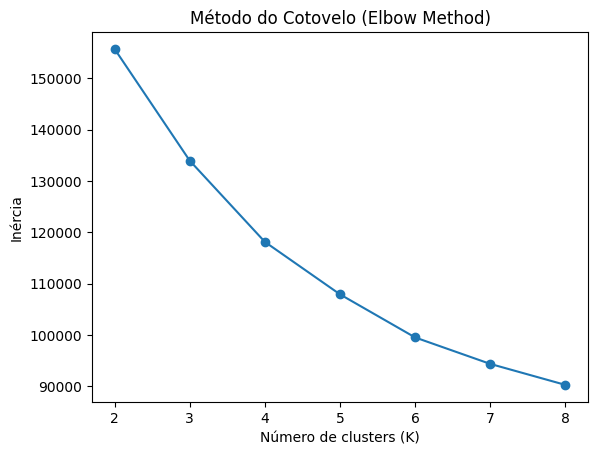

In [10]:
inertias = []
Ks = range(2, 9)

for k in Ks:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10, max_iter=300)
    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_)

plt.figure()
plt.plot(list(Ks), inertias, marker='o')
plt.title('Método do Cotovelo (Elbow Method)')
plt.xlabel('Número de clusters (K)')
plt.ylabel('Inércia')
plt.show()


Com base no gráfico do método do cotovelo, é escolhido um valor de **K** que represente um bom compromisso entre simplicidade do modelo e qualidade de agrupamento.


### 6.2 Treino do Modelo Final de K-Means

Após a análise pelo método do cotovelo, foi selecionado um valor de **K** (por exemplo, K = 4) para treinar o modelo final de K-Means.


In [11]:
best_k = 4  # ajustar se necessário após análise do gráfico Elbow

kmeans_final = KMeans(n_clusters=best_k, random_state=42, n_init=10, max_iter=300)
cluster_labels = kmeans_final.fit_predict(X_scaled)

# Guardar o número do cluster no dataframe original
df['cluster'] = cluster_labels

for c in sorted(df['cluster'].unique()):
    print(f"\n=== Jogadores do Cluster {c} ===")
    display(df[df['cluster'] == c][['name', 'overall_rating', 'age', 'value_euro', 'cluster']].head(3))



=== Jogadores do Cluster 0 ===


,name,overall_rating,age,value_euro,cluster
593,Marcelo,74,29,4600000.0,0
912,Fábio Pacheco,72,30,2300000.0,0
930,K. Kusk,72,27,3300000.0,0



=== Jogadores do Cluster 1 ===


,name,overall_rating,age,value_euro,cluster
182,Herrerín,79,31,8000000.0,1
214,W. Benítez,78,26,9500000.0,1
217,M. Sportiello,78,26,8500000.0,1



=== Jogadores do Cluster 2 ===


,name,overall_rating,age,value_euro,cluster
66,Pau López,82,24,21500000.0,2
70,Gonçalo Guedes,82,22,29000000.0,2
73,F. de Jong,82,21,31000000.0,2



=== Jogadores do Cluster 3 ===


,name,overall_rating,age,value_euro,cluster
0,L. Messi,94,31,110500000.0,3
1,C. Eriksen,88,27,69500000.0,3
2,P. Pogba,88,25,73000000.0,3


## 7. Otimização de Parâmetros

A otimização do algoritmo K-Means foi feita principalmente através da escolha do número de clusters **K**, usando o **Método do Cotovelo (Elbow)**.

Para cada valor de K testado:
- O modelo foi treinado com os mesmos dados normalizados;  
- Foi calculada a inércia (soma das distâncias intra-cluster);  
- O valor de K foi escolhido com base na redução relativa da inércia.

Assim, o valor final de **K** utilizado procura equilibrar a **compactação** dos clusters com a **simplicidade** do modelo.


## 8. Características dos Clusters

Nesta secção são analisadas as características de cada cluster com base em:

- **Número de elementos** por cluster;  
- **Estatísticas descritivas** (média, desvio padrão, mínimo e máximo) dos atributos numéricos;  
- Distribuição do atributo categórico **positions** em cada cluster.


### 8.1 Número de Elementos por Cluster


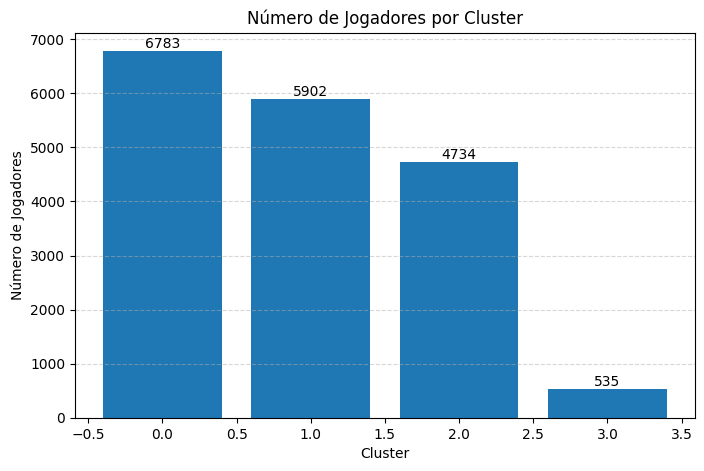

In [12]:
import matplotlib.pyplot as plt

cluster_counts = df['cluster'].value_counts().sort_index()

plt.figure(figsize=(8, 5))
plt.bar(cluster_counts.index, cluster_counts.values)

plt.xlabel('Cluster')
plt.ylabel('Número de Jogadores')
plt.title('Número de Jogadores por Cluster')
plt.grid(axis='y', linestyle='--', alpha=0.5)

for i, value in enumerate(cluster_counts.values):
    plt.text(cluster_counts.index[i], value, str(value),
             ha='center', va='bottom')

plt.show()


Este gráfico mostra quantos jogadores ficaram em cada cluster. Cada barra corresponde a um cluster e a altura mostra o número de jogadores nesse grupo. É útil para perceber se os clusters ficaram equilibrados ou se alguns grupos têm muito mais jogadores do que outros.

### 8.2 Estatísticas Descritivas dos Atributos Numéricos


In [13]:
cluster_stats = df.groupby('cluster')[numeric_cols].agg(['mean', 'std', 'min', 'max'])
cluster_stats

age                     height_cm                            \
              mean       std min max        mean        std    min     max   
cluster                                                                      
0        24.051894  4.427064  17  42  165.248288  11.559573  152.4  193.04   
1        26.497289  4.803607  17  46  187.220637   5.118156  152.4  205.74   
2        26.309675  4.482329  17  42  173.327905  13.233648  152.4  200.66   
3        27.889720  3.670536  18  41  176.836224  13.851218  152.4  198.12   

        weight_kgs                        overall_rating                    \
              mean       std   min    max           mean       std min max   
cluster                                                                      
0        70.628262  4.898423  49.9   88.9      62.079021  5.129632  47  74   
1        81.151728  5.337747  63.0  110.2      64.609116  5.323738  47  79   
2        74.497043  6.230559  52.2  101.2      72.430292  3.794714  57  83   
3        77.115888  7.656626  59.0   99.8      82.216822  3.250136  75  94   

         potential                      value_euro                           \
              mean       std min max          mean           std        min   
cluster                                                                       
0        68.969483  4.833999  52  85  5.333400e+05  4.378237e+05    20000.0   
1        69.063029  4.864414  48  84  8.220927e+05  1.029265e+06    10000.0   
2        76.484368  4.332532  66  90  4.739261e+06  3.792909e+06   100000.0   
3        84.044860  3.810326  75  95  2.521963e+07  1.710933e+07  1700000.0   

                         wage_euro                                  \
                 max          mean           std     min       max   
cluster                                                              
0          4600000.0   2706.811745   2543.312894  1000.0   30000.0   
1         10000000.0   4172.947858   4920.000060  1000.0   46000.0   
2         31000000.0  17500.107458  14266.316404  1000.0  115000.0   
3        110500000.0  96280.373832  70278.711380  1000.0  565000.0   

        international_reputation(1-5)                   weak_foot(1-5)  \
                                 mean       std min max           mean   
cluster                                                                  
0                            1.003243  0.056863   1   2       2.944272   
1                            1.023890  0.154923   1   3       2.687564   
2                            1.201732  0.423867   1   3       3.226236   
3                            2.657944  0.755013   1   5       3.328972   

                          skill_moves(1-5)                   club_rating  \
              std min max             mean       std min max        mean   
cluster                                                                    
0        0.587511   1   5         2.390388  0.545247   1   4   66.856046   
1        0.631043   1   5         1.784649  0.592172   1   4   67.971007   
2        0.658238   1   5         2.954161  0.625038   1   5   73.397338   
3        0.776650   1   5         3.099065  1.059777   1   5   80.786916   

                               
              std   min   max  
cluster                        
0        3.675413  54.0  85.0  
1        4.009528  54.0  86.0  
2        3.852214  62.0  86.0  
3        3.794266  64.0  86.0

### 8.3 Distribuição do Atributo Categórico: positions


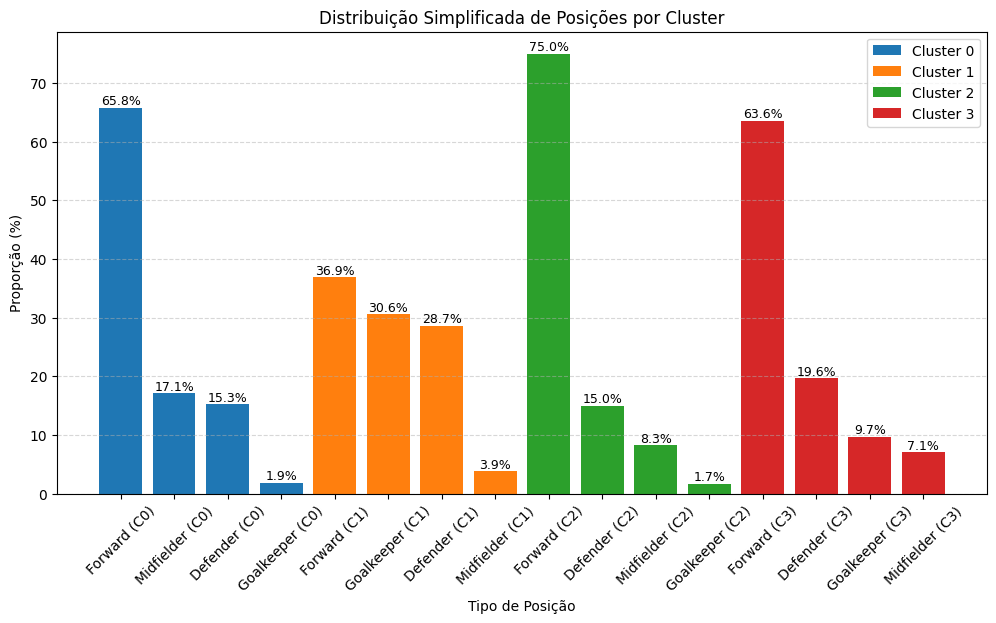

In [16]:
import matplotlib.pyplot as plt

# 1. Simplificar posições
def simplify_position(pos):
    if pos == 'GK':
        return 'Goalkeeper'
    elif pos in ['CB','LCB','RCB','LB','LWB','RB','RWB']:
        return 'Defender'
    elif pos in ['CM','CDM','CAM','LM','RM']:
        return 'Midfielder'
    else:
        return 'Forward'

df['pos_simple'] = df['positions'].apply(simplify_position)

# 2. Calcular proporções manualmente (sem MultiIndex!)
rows = []

for cluster in sorted(df['cluster'].unique()):
    sub = df[df['cluster'] == cluster]
    counts = sub['pos_simple'].value_counts(normalize=True) * 100

    for pos, prop in counts.items():
        rows.append({
            'cluster': cluster,
            'pos_simple': pos,
            'proportion': prop
        })

pos_simple_dist = pd.DataFrame(rows)

plt.figure(figsize=(12, 6))

for cluster in pos_simple_dist['cluster'].unique():
    subset = pos_simple_dist[pos_simple_dist['cluster'] == cluster]
    
    bars = plt.bar(
        subset['pos_simple'] + f" (C{cluster})",
        subset['proportion'],
        label=f'Cluster {cluster}'
    )
    
    # Adicionar valores em cima de cada barra
    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            height,
            f'{height:.1f}%',
            ha='center',
            va='bottom',
            fontsize=9
        )

plt.xlabel('Tipo de Posição')
plt.ylabel('Proporção (%)')
plt.title('Distribuição Simplificada de Posições por Cluster')
plt.xticks(rotation=45)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

## 9. Conclusão

### 9.1 Análise dos Resultados

A aplicação do algoritmo **K-Means** ao dataset FIFA permitiu agrupar jogadores em diferentes clusters com base em atributos numéricos como idade, overall, potential, valor de mercado, salário e outros.

A análise das estatísticas descritivas mostrou que:
- Alguns clusters concentram jogadores com **overall** e **potential** elevados, associados a valores de mercado e salários mais altos;  
- Outros clusters incluem jogadores com valores intermédios ou mais baixos, representando perfis de jogadores de rotação ou com menor impacto;  
- A distribuição do atributo **positions** por cluster indicou que certos grupos são dominados por posições específicas (por exemplo, defesas, médios ou avançados).

### 9.2 Lições Aprendidas

- A **normalização** dos dados é essencial para o desempenho do K-Means, devido à sensibilidade à escala dos atributos;  
- A escolha do número de clusters **K** tem impacto direto na interpretação dos resultados, sendo o **Método do Cotovelo** uma abordagem prática para apoiar essa decisão;  
- A combinação de atributos numéricos com a análise de atributos categóricos (como **positions**) facilita a interpretação dos **perfis de jogadores** em cada cluster;  
- Documentar cada etapa (seleção de dados, preparação, treino, avaliação e análise) torna o processo mais transparente e reprodutível.

Este notebook conclui a parte de **Clustering** do Projeto 02.
